# 2 · Uncertainty, disease-course variability and sensitivity

A single run answers "what happened with seed 42". This notebook asks three follow-up questions:
1. **How much do results vary between runs?** Each scenario is run with 50 seeds, and the median and 90% interval are reported.
2. **What changes if agents do not all follow the same symptom timeline?** In stochastic progression, stage durations vary between agents, and an agent enters the severe stage with a probability that depends on its immunity (strong 30%, normal 60%, weak 90%). Otherwise it stays in its last mild stage until recovery.
3. **Which unstated settings drive the results?** A Morris elementary-effects screening varies 13 settings the report leaves open over plausible ranges (280 runs of the lower respiratory scenario).

In [1]:
from IPython.display import Image, display
import pandas as pd

from epidemic_abm import pipeline

pd.set_option("display.precision", 4)
FIGURES = pipeline.FIGURES


def show(name):
    display(Image(filename=str(FIGURES / name)))


ensembles = pipeline.ensembles()   # 50 seeds per scenario + stochastic progression for the LRTI scenario

In [2]:
from epidemic_abm.pipeline import ENSEMBLE_METRICS
from epidemic_abm.ensemble import interval

def fmt(d, f):
    return f"{f.format(d['median'])} ({f.format(d['low'])}–{f.format(d['high'])})"

formats = {"attack_rate": "{:.1%}", "case_fatality": "{:.1%}", "r_early": "{:.2f}", "r_report_peak": "{:.2f}"}
pd.DataFrame({
    ens.scenario.name + (" — stochastic progression" if key.endswith("stochastic") else ""): {
        metric: fmt(interval(ens.metric(getter)), formats.get(metric, "{:,.0f}"))
        for metric, getter in ENSEMBLE_METRICS.items()
    }
    for key, ens in ensembles.items()
}).T

,attack_rate,peak_infected,peak_day,deaths,case_fatality,r_early,r_report_peak
Upper respiratory tract infection,100.0% (100.0%–100.0%),"10,014 (9,858–10,214)",9 (9–9),0 (0–0),0.0% (0.0%–0.0%),1.90 (1.86–1.92),1.70 (1.70–1.71)
Lower respiratory tract infection,76.7% (75.7%–78.3%),"8,477 (8,307–8,726)",7 (7–8),"4,981 (4,857–5,120)",43.2% (42.7%–44.1%),2.07 (2.03–2.13),1.72 (1.72–1.72)
MeV-1-like high-lethality infection,10.4% (9.9%–10.8%),"1,550 (1,476–1,612)",3 (3–4),"1,100 (1,039–1,153)",70.9% (69.4%–72.6%),0.72 (0.70–0.75),1.54 (1.53–2.16)
Lower respiratory tract infection — stochastic progression,66.0% (63.2%–67.7%),"7,084 (6,736–7,325)",7 (7–7),"2,584 (2,444–2,657)",26.0% (25.2%–26.5%),2.08 (2.05–2.10),1.72 (1.72–1.72)


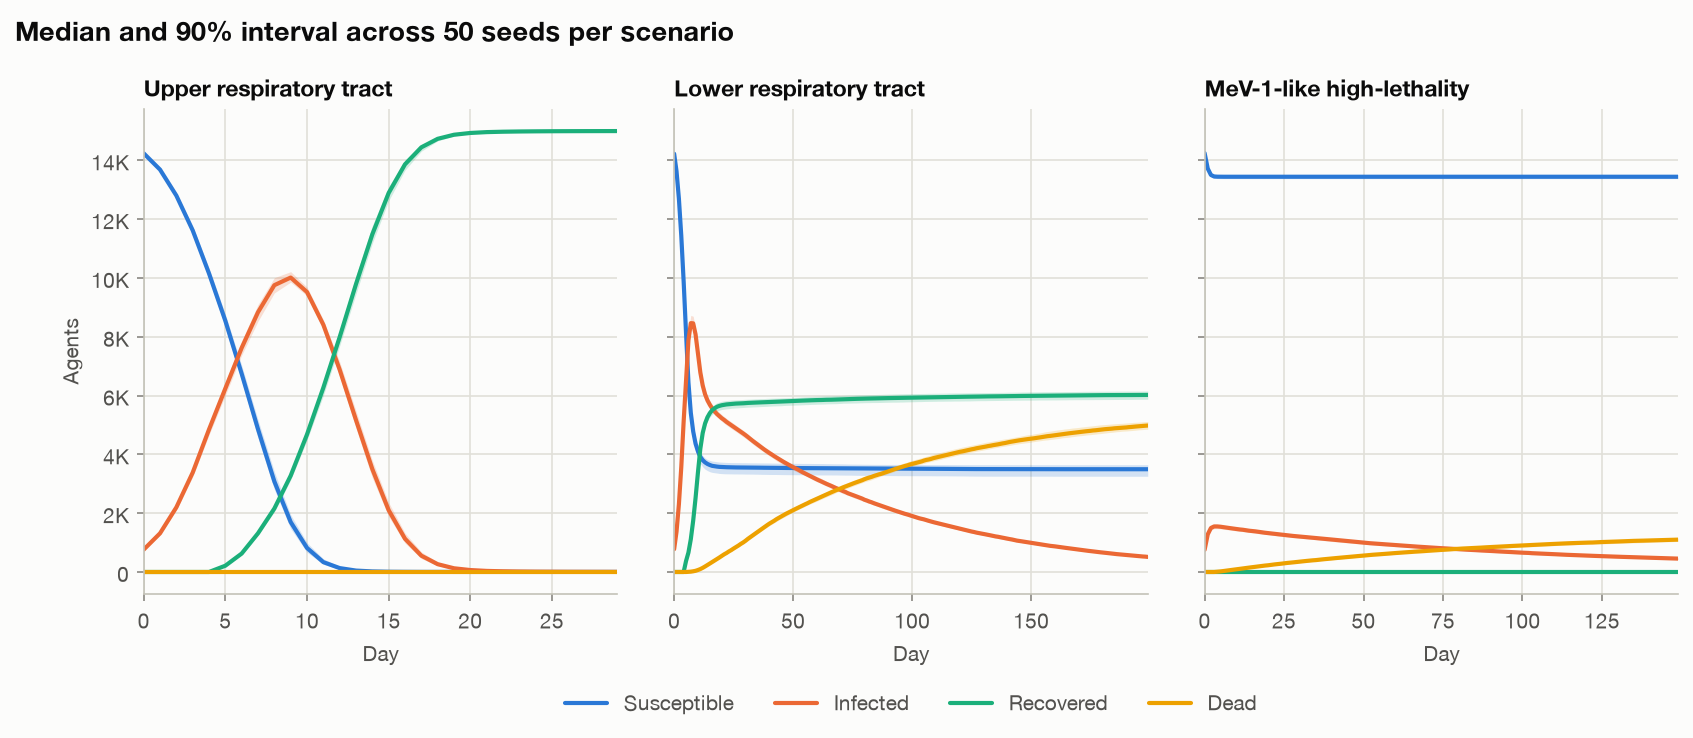

In [3]:
show("ensemble_sird.png")

- **Seed variation is small at 15,000 agents.** For example:
  - Lower respiratory deaths: 4,981 (4,857–5,120).
  - Upper respiratory peak: 10,014 (9,858–10,214).

  The single-seed results in notebook 1 are representative, so the uncertainty that matters comes from the model's assumptions (below), not from chance.
- **Measured early R across seeds:**
  - Upper respiratory: 1.90 (1.86–1.92).
  - Lower respiratory: 2.07 (2.03–2.13).
  - MeV-1-like: 0.72 (0.70–0.75), below 1, so that outbreak cannot sustain itself.

## Fixed timeline vs stochastic progression

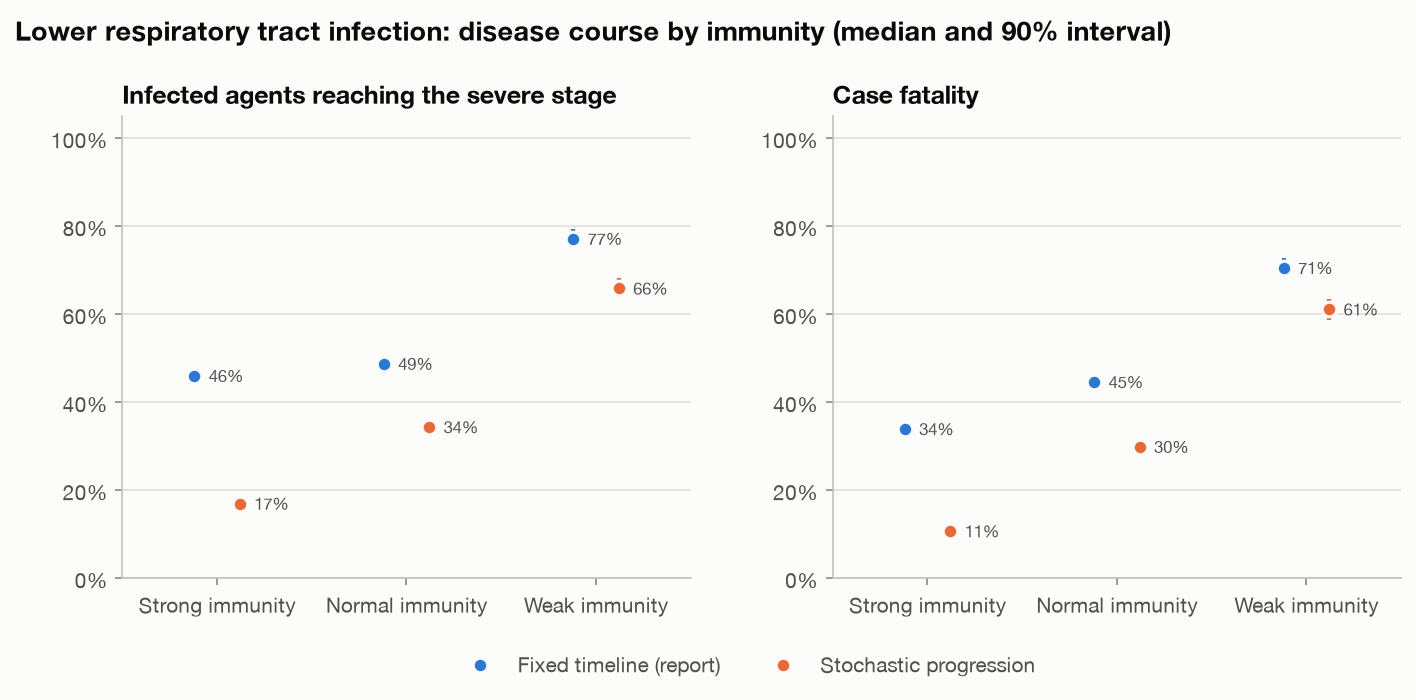

In [4]:
show("lrti_progression.png")

- **Fewer deaths:** with stochastic progression, lower respiratory deaths fall from 4,981 (4,857–5,120) to 2,584 (2,444–2,657), close to the ≈2,500 reported in the report. The attack rate also falls, from 76.7% (75.7%–78.3%) to 66.0% (63.2%–67.7%).
- **Immunity matters more:** severe disease and death become concentrated in the weak-immunity group, which matches the report's observation that pneumonia and high fever "predominantly occur within the weak-immunity subgroup". In the fixed timeline the immunity gradient comes only from faster recovery before day 6, because every agent still ill on day 6 develops pneumonia.

## Morris sensitivity screening

In [5]:
indices, design = pipeline.sensitivity()
indices.pivot(index="factor_label", columns="output_label", values="relative").sort_values("Deaths", ascending=False).round(2)

output_label,Attack rate,Deaths,Peak infected
factor_label,,,
Transmission scale,1.00,1.00,1.00
Minimum illness days,0.23,0.95,0.36
Health loss per unit severity,0.08,0.65,0.01
Death-risk scale,0.03,0.52,0.03
Network neighbours (k),0.51,0.49,0.65
Initially infected share,0.48,0.43,0.52
Isolation group size,0.42,0.42,0.29
Seats per table,0.44,0.37,0.29
Network rewiring probability,0.34,0.28,0.40


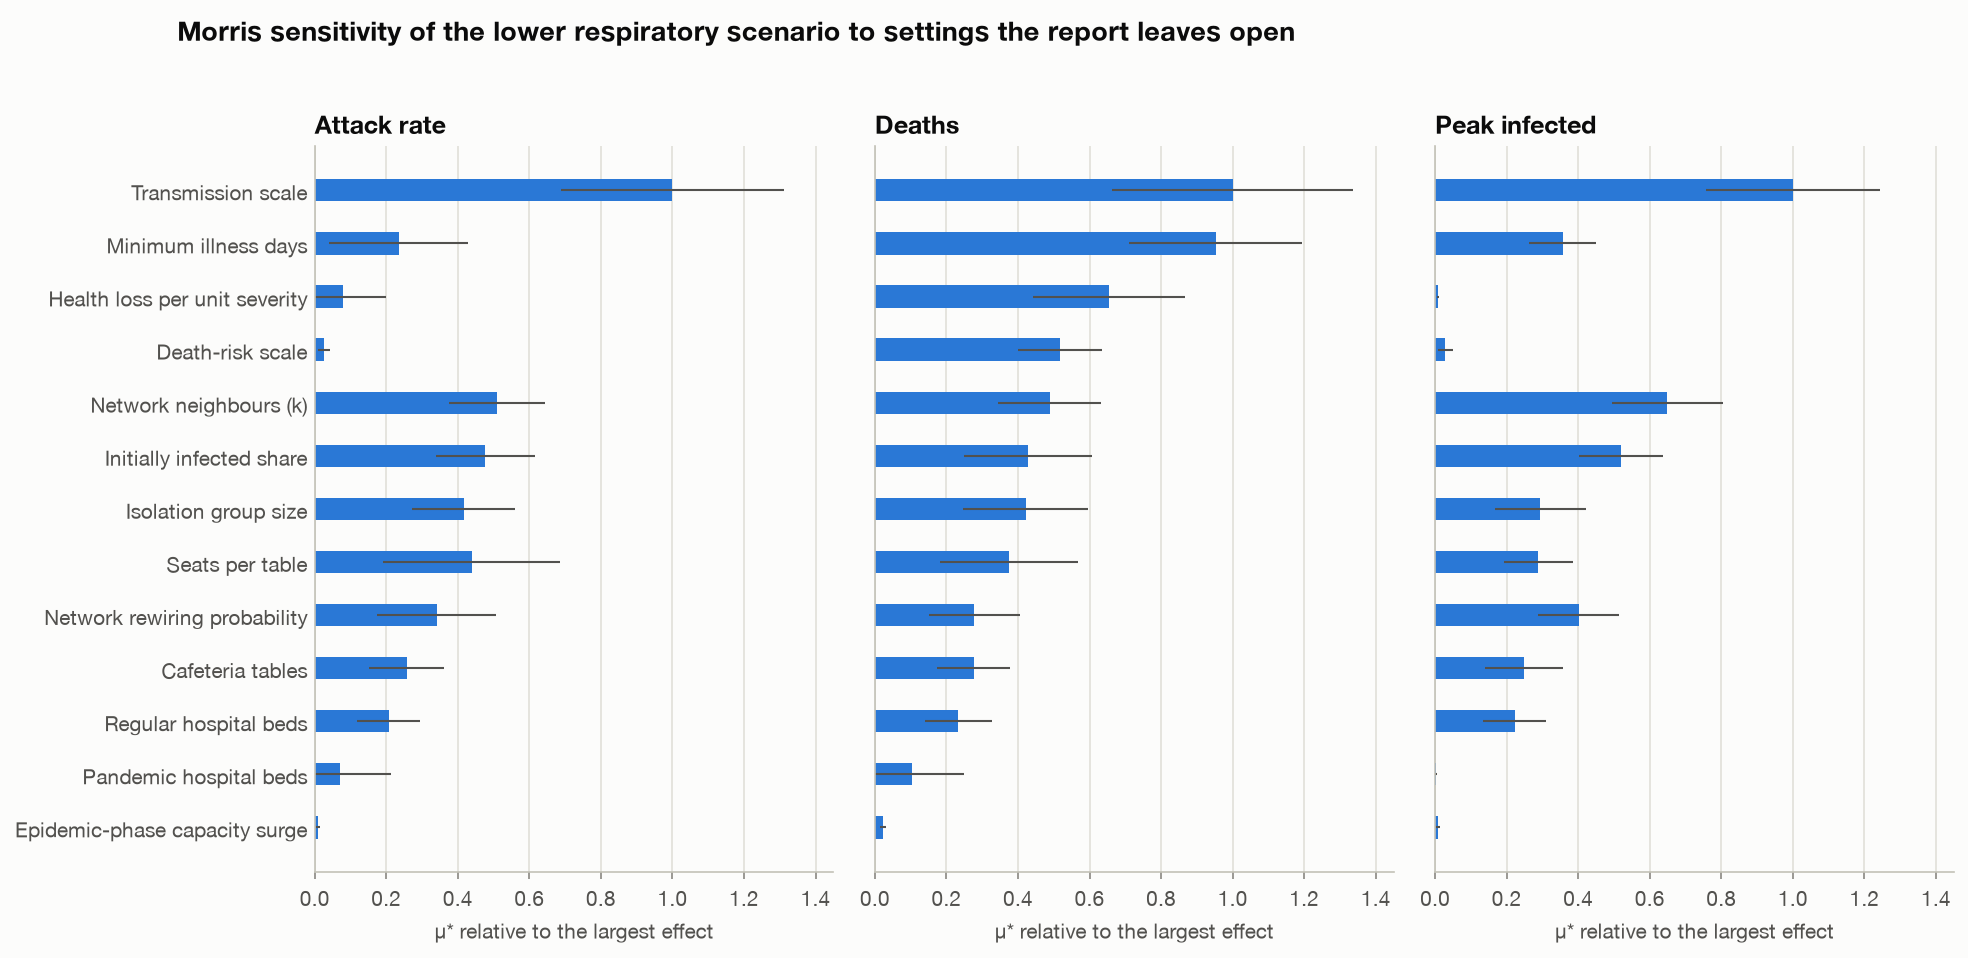

In [6]:
show("lrti_sensitivity.png")

μ* is the mean absolute change in an output when a setting moves one step across its range. The table shows it relative to the most influential setting.

- **Deaths** depend most on transmission scale, minimum illness days, health loss per unit severity and death-risk scale. The last three are recovery and mortality assumptions that the report does not quantify, so death counts are the least robust output of the model.
- **Attack rate and peak** depend mostly on transmission and contact structure: transmission scale, network neighbours (k) and initially infected share.
- **Epidemic-phase capacity surge** has almost no effect on any output.
- Large σ relative to μ* (see `indices`) indicates strong interactions between settings, typical for threshold-driven mechanisms such as the epidemic-day trigger.